# Mission and propulsion

Continue the ascent through coast, restart, and trans-Mars injection (TMI).
This uses the same 6DOF equations and the actual ascent cutoff state.
It checks departure energy; it does not solve the full Mars intercept.


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from hyperion.workspace import current_flight
from hyperion.mission import integrated_tmi, lambert_window
from hyperion.trajectory import MU
from hyperion.verification import ROOT, input_contracts

%matplotlib inline


## 1. Set the departure assumptions

Edit the three values below for this notebook's study. The burn points
along the velocity vector and stops at the energy target, minimum propellant
reserve, ground contact, or time limit.

**C3** measures departure energy. Negative C3 means the spacecraft is still
bound to Earth. The master case uses **7.7058 km²/s²**; the requirement uses
**9.8 km²/s²**, still under review. Coast duration and restart consumption
are assumptions. No coast-control authority is currently allocated.
To change the register's run too, update [verification_inputs.json](config/verification_inputs.json).


In [2]:
context = current_flight()
_, _, model = context

COAST_SECONDS = 600.0
RESTART_PROPELLANT_KG = model.c["vehicle"]["stages"][1]["startup_propellant_kg"]
TARGET_C3 = 9.8  # km²/s²

tmi = integrated_tmi(
    context=context,
    coast_duration_s=COAST_SECONDS,
    restart_propellant_kg=RESTART_PROPELLANT_KG,
    target_c3_km2_s2=TARGET_C3,
    max_burn_duration_s=900,
    output_step_s=2,
)
print("Burn ended because:", tmi["status"].replace("_", " "))
results = [
    ("Target C3", tmi["target_C3_km2_s2"], "km²/s²"),
    ("Achieved C3", tmi["achieved_C3_km2_s2"], "km²/s²"),
    ("C3 margin", tmi["C3_margin_km2_s2"], "km²/s²"),
    ("Propellant remaining", tmi["remaining_propellant_kg"], "kg"),
    ("Required reserve", tmi["required_residual_kg"], "kg"),
]
display(pd.DataFrame(results, columns=["Result", "Value", "Unit"]).round(3))


Burn ended because: residual propellant limit


,Result,Value,Unit
0,Target C3,9.800,km²/s²
1,Achieved C3,-12.254,km²/s²
2,C3 margin,-22.054,km²/s²
3,Propellant remaining,1917.146,kg
4,Required reserve,1917.146,kg


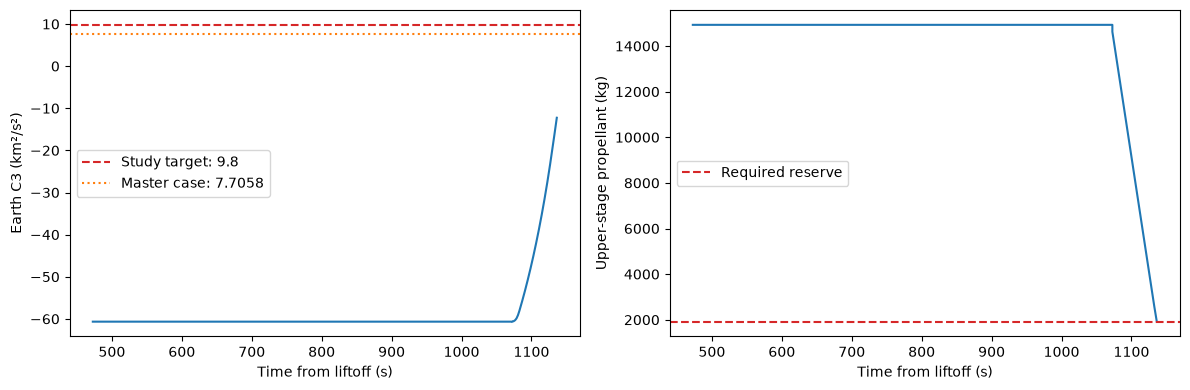

In [3]:
departure = pd.DataFrame(tmi["history"])
position = departure[["eci_x_m", "eci_y_m", "eci_z_m"]].to_numpy()
velocity = departure[["eci_vx_m_s", "eci_vy_m_s", "eci_vz_m_s"]].to_numpy()
radius = np.linalg.norm(position, axis=1)
speed_squared = np.sum(velocity**2, axis=1)
departure_c3 = (speed_squared - 2 * MU / radius) / 1e6

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(departure.t_s, departure_c3)
axes[0].axhline(
    TARGET_C3, linestyle="--", color="tab:red", label=f"Study target: {TARGET_C3:g}"
)
axes[0].axhline(7.7058, linestyle=":", color="tab:orange", label="Master case: 7.7058")
axes[0].set(xlabel="Time from liftoff (s)", ylabel="Earth C3 (km²/s²)")
axes[0].legend()

axes[1].plot(departure.t_s, departure.prop2_kg)
axes[1].axhline(
    tmi["required_residual_kg"],
    linestyle="--",
    color="tab:red",
    label="Required reserve",
)
axes[1].set(xlabel="Time from liftoff (s)", ylabel="Upper-stage propellant (kg)")
axes[1].legend()
figure.tight_layout()
plt.show()


## 2. Check the source departure dates

These three Earth–Mars transfers use the team's Horizons states for
**27–29 April 2033** and a **274-day** flight time. The input file records the
Sun-centered ICRF frame and TDB times. This small sample checks the solver
and data; launch windows still need site timing and finite-burn targeting.


In [4]:
mission_file = ROOT / "config/mission_cases.json"
mission_cases = json.loads(mission_file.read_text(encoding="utf-8"))
window = lambert_window(
    cases=mission_cases["cases"],
    central_mu_m3_s2=mission_cases["central_mu_m3_s2"],
)
columns = {
    "departure_label": "Departure date",
    "departure_C3_km2_s2": "C3 (km²/s²)",
    "departure_declination_deg": "Declination (deg)",
    "arrival_excess_speed_m_s": "Arrival excess speed (m/s)",
}
display(pd.DataFrame(window["cases"])[list(columns)].rename(columns=columns).round(4))


,Departure date,C3 (km²/s²),Declination (deg),Arrival excess speed (m/s)
0,2033-04-27 00:00 TDB,7.7237,-10.3665,4375.8107
1,2033-04-28 00:00 TDB,7.7090,-11.3763,4376.2099
2,2033-04-29 00:00 TDB,7.7055,-12.4805,4376.2699


## 3. Find inputs for another calculation

Change `CALCULATION` below to inspect one function. Examples include
`thrust_flow`, `nozzle`, and `integrated_tmi`. The full list is in
[calculation_inputs.csv](data/calculation_inputs.csv).

Supply actual geometry, thermochemistry, pressures, and controller settings
before using a result as design evidence. Hot-fire and hardware test results
need their own reviewed records.


In [5]:
CALCULATION = "thrust_flow"
calculations = input_contracts().set_index("calculation")
selected = calculations.loc[CALCULATION]
print(selected["description"])
display(pd.DataFrame({"Required input": selected["required_inputs"].split(", ")}))


Propellant flow in kg/s from thrust in N and specific impulse in seconds.


,Required input
0,thrust_N
1,isp_s
